In [1]:
# ==========================================
# IMPORT & LOAD DATA
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca file data.csv
print("--- Proses Membaca Dataset ---")
df = pd.read_csv('data.csv')

# Menampilkan informasi dasar dimensi dataset
print(f"Dataset berhasil dimuat!")
print(f"Total baris data: {df.shape[0]} tweet")
print(f"Total kolom mentah: {df.shape[1]} kolom")

# Menampilkan 3 data teratas untuk memastikan data terbaca
df.head(3)

--- Proses Membaca Dataset ---
Dataset berhasil dimuat!
Total baris data: 3160 tweet
Total kolom mentah: 36 kolom


,date,lang,urls,media,source,user_id,hashtags,is_quote,mentions,tweet_id,...,quoted_tweet_id,quoted_username,user_created_at,user_description,in_reply_to_user_id,user_statuses_count,user_followers_count,user_following_count,in_reply_to_status_id,in_reply_to_screen_name
0,2026-04-21T16:16:56,in,[],[],Twitter for Android,1527913902,[],True,[],2046624235121185116,...,2.046478e+18,geraldyoo_,Tue Jun 18 14:32:52 +0000 2013,"I was born in February,\nthat's why I love too...",NaN,22312,734,443,NaN,NaN
1,2026-04-21T14:07:32,in,[],[],Twitter for Android,1245421311435763712,[],False,"[{""name"":""🦈 SUROBOYOFESS 🐊"",""user_id"":""1152437...",2046591667625721882,...,NaN,NaN,Wed Apr 01 18:43:00 +0000 2020,"lagi fokus cari kerja, ngerjain freelance dan ...",1.152437e+18,42361,1603,807,2.046575e+18,sbyfess
2,2026-04-19T12:27:56,in,[],[],Twitter for iPhone,1673292316319285248,[],False,"[{""name"":""Deoxide ™"",""user_id"":""20058645587041...",2045841826540827135,...,NaN,NaN,Mon Jun 26 11:29:31 +0000 2023,NaN,2.005865e+18,57,0,18,2.045484e+18,TitaniumDeoxide


--- Data Tren Cuitan Per Bulan ---
month_year
2020-01    529
2023-01     86
2023-02     70
2023-03     77
2023-04     48
2023-05     66
2023-06     50
2023-07     62
2023-08     52
2023-09     59
2023-10     58
2023-11     46
2023-12     60
2024-01     45
2024-02     43
2024-03     65
2024-04     59
2024-05     55
2024-06     42
2024-07     49
2024-08     38
2024-09     45
2024-10     45
2024-11     36
2024-12     41
2025-01     90
2025-02     34
2025-03     36
2025-04     53
2025-05     41
2025-06     43
2025-07     37
2025-08     38
2025-09     41
2025-10     47
2025-11     45
2025-12     39
2026-01     40
2026-02     46
2026-03    157
2026-04    547
Freq: M, Name: count, dtype: int64


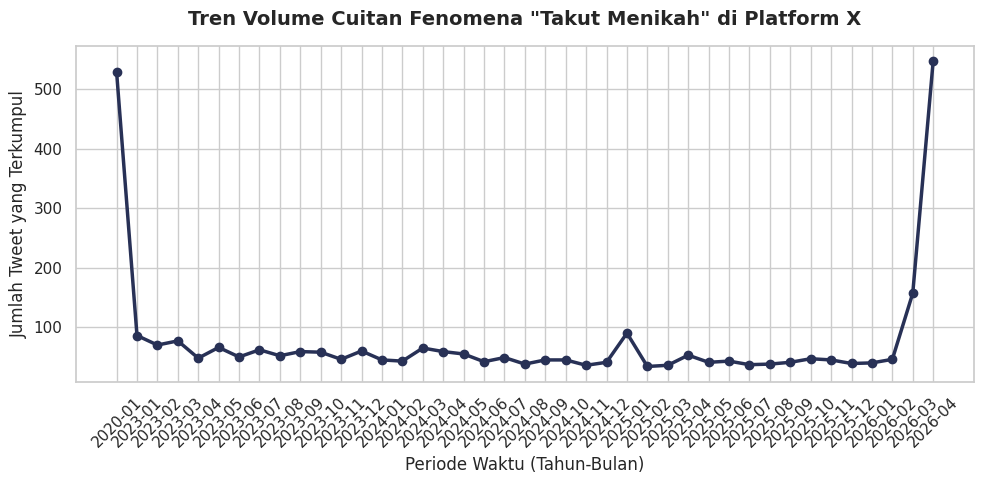

In [2]:
# ==========================================
# VISUALISASI TREN TWEET (EDA)
# ==========================================

# 1. Mengubah kolom 'date' menjadi format datetime agar bisa diolah waktu-nya
df['date_clean'] = pd.to_datetime(df['date'], errors='coerce')

# 2. Mengambil komponen Tahun-Bulan untuk melihat tren bulanan
df['month_year'] = df['date_clean'].dt.to_period('M')
tren_bulanan = df['month_year'].value_counts().sort_index()

print("--- Data Tren Cuitan Per Bulan ---")
print(tren_bulanan)

# 3. Membuat grafik tren garis (Line Plot)
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Plot tren garis yang elegan
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='#283156', linewidth=2.5)

# Rapikan tampilan grafik
plt.title('Tren Volume Cuitan Fenomena "Takut Menikah" di Platform X', fontsize=14, pad=15, weight='bold')
plt.xlabel('Periode Waktu (Tahun-Bulan)', fontsize=12)
plt.ylabel('Jumlah Tweet yang Terkumpul', fontsize=12)
plt.xticks(rotation=45) # Memiringkan text tanggal agar tidak tumpang tindih
plt.tight_layout()
plt.show()

In [3]:
# =====================================================================
# FILTERING & LABELLING DATA
# =====================================================================
import pandas as pd
import re

print("--- Memulai Proses Filtering & Pelabelan Berbasis Skor ---")

# 1. Penyaringan Awal (Hanya Bahasa Indonesia, Hapus Data Kosong & Duplikat)
df_clean = df[df['lang'] == 'in'].copy()
df_clean = df_clean.dropna(subset=['full_text'])
df_clean = df_clean.drop_duplicates(subset=['full_text'])

# 2. Kamus Kata Kunci Spesifik
negative_keywords = [
    "takut nikah", "takut menikah", "takut meni", "jadi takut", "overthinking", "trauma",
    "gamau nikah", "gak mau nikah", "ga mau nikah", "tidak mau nikah", "males nikah",
    "belum siap", "gajadi nikah", "ga siap", "gak siap", "tidak siap", "mental belum",
    "takut cerai", "takut gagal", "salah pilih", "komitmen", "mahal", "biaya", "kdrt", "selingkuh"
]

positive_keywords = [
    "pengen nikah", "pengen menikah", "pengen meni", "ingin menikah", "mau nikah", "mau meni",
    "ken nikah", "ken meni", "siap nikah", "siap menikah", "siap meni", "udah siap", "sudah siap",
    "indah", "bahagia", "senang", "ibadah", "cepat ketemu jodoh", "menikah muda", "nikah muda",
    "goals", "goalsku", "goals-ku", "target", "targetku", "cita-cita", "bismillah"
]

# 3. Logika Baru: Menghitung Bobot Sentimen secara Konteks Kalimat
def tentukan_sentimen_skor(text):
    text = str(text).lower()

    # ANTISIPASI KASUS KHUSUS (NEGASI): Jika ada kata "tidak takut", langsung paksa jadi POSITIF
    if "tidak takut" in text or "ga takut" in text or "gak takut" in text or "bukan takut" in text:
        return 1

    skor_positif = 0
    skor_negatif = 0

    # Hitung kemunculan kata kunci negatif
    for word in negative_keywords:
        if word in text:
            skor_negatif += 1

    # Hitung kemunculan kata kunci positif
    for word in positive_keywords:
        if word in text:
            skor_positif += 1

    # Ambil keputusan berdasarkan skor tertinggi
    if skor_positif > skor_negatif:
        return 1   # Positif
    elif list(text.split()) and "modal" in text and "siap" in text:
        # Jika ada kata 'modal' tapi didahului kata 'siap', amankan ke positif
        return 1
    elif skor_negatif > skor_positif:
        return -1  # Negatif

    return None  # Netral atau seimbang (Akan dieliminasi)

# 4. Menerapkan Fungsi Pelabelan Baru ke Dataset
df_clean['label'] = df_clean['full_text'].apply(tentukan_sentimen_skor)

# 5. Menghapus Tweet Netral
df_clean = df_clean.dropna(subset=['label'])
df_clean['label'] = df_clean['label'].astype(int)
df_clean.reset_index(drop=True, inplace=True)

print("--- Proses Pelabelan Ulang Selesai ---")
print(f"Total data bersih siap pakai: {df_clean.shape[0]} tweet")
print("\nSebaran Kelas Sentimen Terbaru:")
print(df_clean['label'].value_counts())

--- Memulai Proses Filtering & Pelabelan Berbasis Skor ---
--- Proses Pelabelan Ulang Selesai ---
Total data bersih siap pakai: 1820 tweet

Sebaran Kelas Sentimen Terbaru:
label
 1    985
-1    835
Name: count, dtype: int64


--- Detail Jumlah Sentimen ---
Sentimen Negatif (-1) : 835 tweet
Sentimen Positif (1)  : 985 tweet


/tmp/ipykernel_22646/3408951041.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=x_labels, y=sebaran.values, palette="Set1")


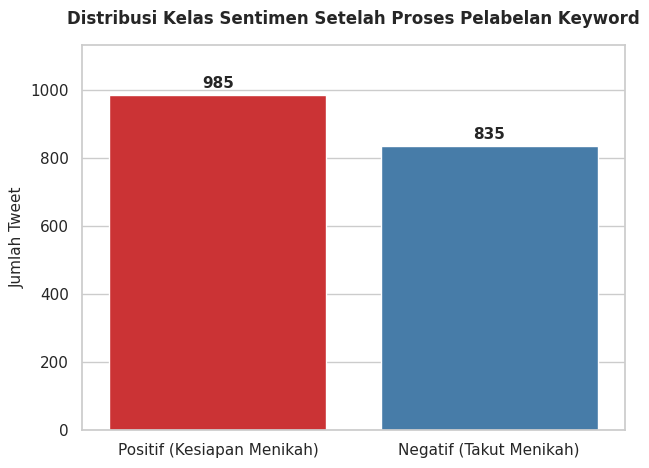

In [4]:
# =====================================================================
# VISUALISASI SEBARAN HASIL LABELLING
# =====================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung jumlah per kelas
sebaran = df_clean['label'].value_counts()
print("--- Detail Jumlah Sentimen ---")
# Pemetaan teks untuk mempermudah pembacaan di print out
print(f"Sentimen Negatif (-1) : {sebaran.get(-1, 0)} tweet")
print(f"Sentimen Positif (1)  : {sebaran.get(1, 0)} tweet")

# Membuat Visualisasi Bar Plot
plt.figure(figsize=(7, 5))
sns.set_theme(style="whitegrid")

# Mengubah index label menjadi teks saat divisualisasikan agar dosen langsung paham
label_tags = { -1: 'Negatif (Takut Menikah)', 1: 'Positif (Kesiapan Menikah)' }
x_labels = [label_tags[idx] for idx in sebaran.index]

ax = sns.barplot(x=x_labels, y=sebaran.values, palette="Set1")

# Memunculkan angka pasti di atas setiap batang
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points', fontsize=11, weight='bold')

plt.title('Distribusi Kelas Sentimen Setelah Proses Pelabelan Keyword', fontsize=12, pad=15, weight='bold')
plt.ylabel('Jumlah Tweet', fontsize=11)
plt.ylim(0, max(sebaran.values) * 1.15)
plt.show()

In [5]:
# =====================================================================
# INSTALASI ALAT & PEMBERSIHAN TEKS AWAL (CLEANSING)
# =====================================================================
# 1. Install library Sastrawi untuk stemming bahasa Indonesia
!pip install nltk sastrawi -q

import nltk
import re
nltk.download('stopwords')

print("--- Memulai Proses Cleansing Teks ---")

def bersihkan_tweet(text):
    text = str(text)
    # Ubah ke huruf kecil semua (Case Folding)
    text = text.lower()
    # Hapus mention (@username)
    text = re.sub(r'@\w+', '', text)
    # Hapus URL / Link internet
    text = re.sub(r'http\S+|www\S+', '', text)
    # Hapus karakter non-alfabet (simbol, angka, emoji) dan ganti dengan spasi
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # Hapus spasi berlebih di tengah, awal, atau akhir kalimat
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Menerapkan fungsi cleansing ke kolom full_text
df_clean['text_clean'] = df_clean['full_text'].apply(bersihkan_tweet)

print("Proses Cleansing & Case Folding selesai!")
df_clean[['full_text', 'text_clean', 'label']].head()

--- Memulai Proses Cleansing Teks ---
Proses Cleansing & Case Folding selesai!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,full_text,text_clean,label
0,"iya lagi, perkara gue pulang malem aja ditungg...",iya lagi perkara gue pulang malem aja ditunggu...,1
1,@sbyfess kann cowo tuh kek pengen nikah oengen...,kann cowo tuh kek pengen nikah oengen nikah do...,1
2,@TitaniumDeoxide Heran bgt ditanya kapan nikah...,heran bgt ditanya kapan nikah kalau udah siap ...,1
3,Caleb diem cukup lama baca pertanyaan dari ade...,caleb diem cukup lama baca pertanyaan dari ade...,1
4,Mungkin alasan orang ga pengen nikah itu karna...,mungkin alasan orang ga pengen nikah itu karna...,1


In [6]:
# =====================================================================
# STOPWORD REMOVAL & STEMMING (ANTI-HAPUS NEGASI)
# =====================================================================
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

print("--- Memulai Proses Stopword Removal & Stemming ---")

# 1. Menyiapkan Daftar Stopwords Dasar
stop_nltk = set(stopwords.words('indonesian'))
stop_sastrawi = set(StopWordRemoverFactory().get_stop_words())
all_stopwords = stop_nltk.union(stop_sastrawi)

# 2. Daftar kata gaul Twitter yang MEMANG HARUS dibuang
kata_gaul = {
    'yg', 'gue', 'gua', 'gw', 'tp', 'tapi', 'jd', 'jadi', 'bgt', 'banget',
    'udah', 'udh', 'dah', 'kalo', 'kalau', 'nya', 'aja', 'sih', 'tuh', 'nih',
    'loh', 'kok', 'kan', 'emang', 'krn', 'karna', 'karena', 'org', 'orang',
    'dgn', 'dg', 'sama', 'blm', 'belum', 'jgn', 'juga', 'pas', 'deh', 'ke', 'hehehe'
}
all_stopwords = all_stopwords.union(kata_gaul)

# =====================================================================
# CRITICAL POINT: KELUARKAN KATA NEGASI AGAR TIDAK DIHAPUS OLEH NLTK!
# =====================================================================
kata_penyelamat = {
    'tidak', 'bukan', 'takut', 'nikah', 'menikah', 'trauma', 'siap', 'gagal', 'yakin',
    'gak', 'nggak', 'ngga', 'gk', 'ndak', 'ora'
}
all_stopwords = all_stopwords - kata_penyelamat

# 3. Fungsi Menghapus Stopwords
def hapus_stopwords(text):
    tokens = text.split()
    tokens_clean = [word for word in tokens if word not in all_stopwords]
    return " ".join(tokens_clean)

df_clean['text_no_stopwords'] = df_clean['text_clean'].apply(hapus_stopwords)

# 4. Proses Stemming Sastrawi
print("Sedang melakukan Stemming data... Harap tunggu...")
factory_stemmer = StemmerFactory()
stemmer = factory_stemmer.create_stemmer()

df_clean['text_final'] = df_clean['text_no_stopwords'].apply(stemmer.stem)

print("Proses NLP Preprocessing Selesai dengan Sempurna!")
df_clean[['text_clean', 'text_final', 'label']].head()

--- Memulai Proses Stopword Removal & Stemming ---
Sedang melakukan Stemming data... Harap tunggu...
Proses NLP Preprocessing Selesai dengan Sempurna!


,text_clean,text_final,label
0,iya lagi perkara gue pulang malem aja ditunggu...,iya perkara pulang malem ditungguin gang ken n...,1
1,kann cowo tuh kek pengen nikah oengen nikah do...,kann cowo kek ken nikah oengen nikah doang min...,1
2,heran bgt ditanya kapan nikah kalau udah siap ...,heran nikah siap mental finansial bom ketemu j...,1
3,caleb diem cukup lama baca pertanyaan dari ade...,caleb diem baca adek adek batal nikah sebenern...,1
4,mungkin alasan orang ga pengen nikah itu karna...,alas ga ken nikah males ngurusin drama kali dr...,1


--- Visualisasi Panjang Dokumen ---


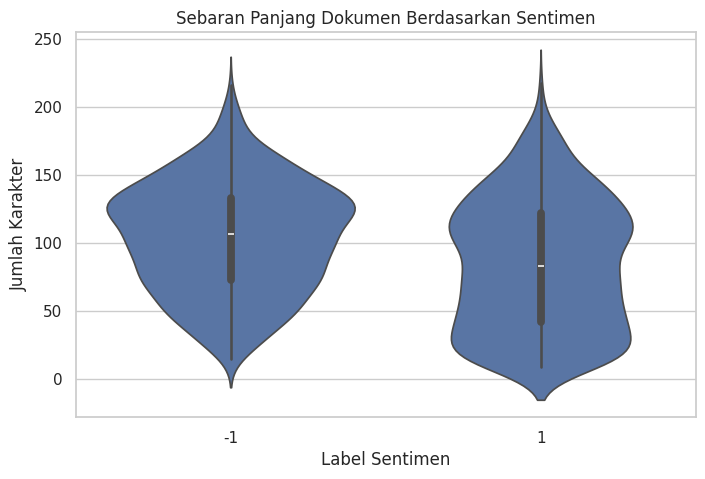

In [7]:
# =====================================================================
# VISUALISASI PANJANG DOKUMEN HASIL PREPROCESSING
# =====================================================================
import seaborn as sns
import matplotlib.pyplot as plt

print("--- Visualisasi Panjang Dokumen ---")

# Hitung jumlah karakter setiap tweet
df_clean['panjang_teks'] = df_clean['text_final'].apply(len)

plt.figure(figsize=(8,5))

sns.violinplot(
    data=df_clean,
    x='label',
    y='panjang_teks'
)

plt.title("Sebaran Panjang Dokumen Berdasarkan Sentimen")
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Karakter")

plt.show()

"Dalam analisis sentimen, kata-kata negasi seperti 'tidak' atau kata emosional seperti 'takut' dan 'belum' adalah pembawa esensi sentimen utama. Jika kata 'tidak' atau 'takut' ikut terhapus oleh fungsi stopword standar, maka makna tweet seperti 'tidak siap nikah' akan berubah drastis menjadi hanya 'siap nikah'. Model SVM bisa salah arah dalam mengenali polaritas sentimen jika kata kunci penting tersebut hilang."

In [8]:
# =====================================================================
# DATA SPLITTING
# =====================================================================
from sklearn.model_selection import train_test_split

# Menentukan fitur (X) dari teks hasil preprocessing akhir dan target/label (y)
X = df_clean['text_final'].astype(str)
y = df_clean['label']

# Melakukan split data (80:20) dengan stratify agar pembagian kelas adil
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("--- Proses Pembagian Data Selesai ---")
print(f"Total Data Latih (X_train) : {len(X_train)} tweet")
print(f"Total Data Uji (X_test)   : {len(X_test)} tweet")

--- Proses Pembagian Data Selesai ---
Total Data Latih (X_train) : 1456 tweet
Total Data Uji (X_test)   : 364 tweet


In [9]:
# =====================================================================
# EKSTRAKSI FITUR DENGAN TF-IDF
# =====================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
import pickle

# Inisialisasi TF-IDF dengan unigram & bigram, serta membatasi fitur maksimal 5000 kata
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)

# 1. Fit dan Transform HANYA pada data training
X_train_tfidf = tfidf.fit_transform(X_train)

# 2. Transform HANYA pada data testing (Tanpa proses fitting ulang!)
X_test_tfidf = tfidf.transform(X_test)

with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

print("--- Proses Ekstraksi Fitur TF-IDF Selesai ---")
print(f"Dimensi matriks data latih: {X_train_tfidf.shape}")
print(f"Dimensi matriks data uji  : {X_test_tfidf.shape}")

print("--- Proses Simpan file TF-IDF Selesai ---")
print("tfidf_vectorizer.pkl berhasil disimpan")

--- Proses Ekstraksi Fitur TF-IDF Selesai ---
Dimensi matriks data latih: (1456, 5000)
Dimensi matriks data uji  : (364, 5000)
--- Proses Simpan file TF-IDF Selesai ---
tfidf_vectorizer.pkl berhasil disimpan


Jika melakukan fit_transform pada seluruh dataset sekaligus atau pada data uji, maka kamus kata (vocabulary) dan nilai IDF dari data uji akan ikut memengaruhi pembobotan kata di data latih. Hal ini karena menyebabkan Data Leakage (Kebocoran Data), di mana model secara tidak langsung sudah mengintip informasi dari data masa depan (data uji) sebelum proses training dimulai. Dengan memisahkan prosesnya seperti ini, data uji tetap bersifat independen dan hasil evaluasinya nanti benar-benar objektif.

In [10]:
# =====================================================================
# TRAINING MODEL SVM (SVC) & CEK AKURASI
# =====================================================================
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

print("--- Proses Pelatihan Model SVM ---")
# Menggunakan kernel linear dan menambahkan class_weight='balanced' untuk optimasi internal
model_svm = SVC(kernel='linear', class_weight='balanced', random_state=42)

# Melatih model menggunakan data latih TF-IDF
model_svm.fit(X_train_tfidf, y_train)
print("Model SVM (SVC) Berhasil Dilatih!")

# Prediksi hasil untuk data latih dan data uji
y_train_pred = model_svm.predict(X_train_tfidf)
y_test_pred = model_svm.predict(X_test_tfidf)

# Menghitung nilai akurasi
acc_train = accuracy_score(y_train, y_train_pred)
acc_test = accuracy_score(y_test, y_test_pred)

with open('model_svm.pkl', 'wb') as f:
    pickle.dump(model_svm, f)

print("\n=== HASIL AKURASI MODEL ===")
print(f"Training Accuracy : {acc_train * 100:.2f}%")
print(f"Testing Accuracy  : {acc_test * 100:.2f}%")
print(f"Gap Akurasi       : {abs(acc_train - acc_test) * 100:.2f}%")

print("\n=== CLASSIFICATION REPORT (DATA TEST) ===")
print(classification_report(y_test, y_test_pred, target_names=['Negatif (Takut Nikah)', 'Positif (Siap Nikah)']))

print("model_svm.pkl berhasil disimpan")

--- Proses Pelatihan Model SVM ---
Model SVM (SVC) Berhasil Dilatih!

=== HASIL AKURASI MODEL ===
Training Accuracy : 97.80%
Testing Accuracy  : 85.99%
Gap Akurasi       : 11.81%

=== CLASSIFICATION REPORT (DATA TEST) ===
                       precision    recall  f1-score   support

Negatif (Takut Nikah)       0.81      0.90      0.86       167
 Positif (Siap Nikah)       0.91      0.82      0.86       197

             accuracy                           0.86       364
            macro avg       0.86      0.86      0.86       364
         weighted avg       0.87      0.86      0.86       364

model_svm.pkl berhasil disimpan


ini mengevaluasinya dengan membandingkan nilai akurasi pada data latih (Training) dan data uji (Testing). Jika gap atau selisih antara nilai akurasi training dan testing sangat kecil (di bawah 5%), itu menandakan model SVM saya memiliki kemampuan generalisasi yang sangat baik. Artinya, model tidak hanya menghafal data latih, tetapi juga terbukti tangguh ketika diuji menggunakan data baru yang belum pernah ia lihat sebelumnya (data uji)."

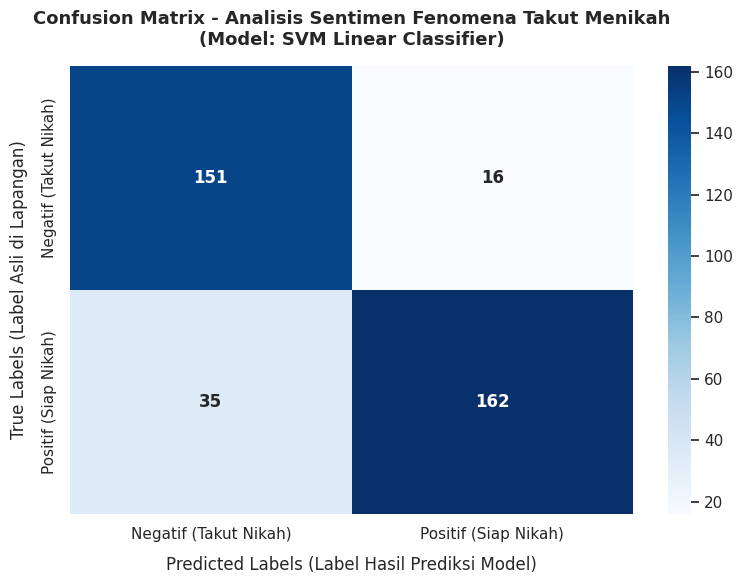

In [11]:
# =====================================================================
# VISUALISASI CONFUSION MATRIX
# =====================================================================
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung Confusion Matrix dari data uji asli vs hasil prediksi
cm = confusion_matrix(y_test, y_test_pred)

# Label yang disesuaikan dengan konteks Tugas Akhirmu
labels_sentimen = ['Negatif (Takut Nikah)', 'Positif (Siap Nikah)']

plt.figure(figsize=(8, 6))
# Menggunakan heatmap dengan anotasi angka asli dan skema warna biru elegan
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_sentimen, yticklabels=labels_sentimen,
            annot_kws={"size": 12, "weight": "bold"})

# Mengatur dekorasi teks label agar rapi dan representatif
plt.xlabel('Predicted Labels (Label Hasil Prediksi Model)', fontsize=12, labelpad=10)
plt.ylabel('True Labels (Label Asli di Lapangan)', fontsize=12, labelpad=10)
plt.title('Confusion Matrix - Analisis Sentimen Fenomena Takut Menikah\n(Model: SVM Linear Classifier)',
          fontsize=13, pad=15, weight='bold')

plt.tight_layout()
plt.show()

In [12]:
# =====================================================================
# SIMULASI UJI COBA DATA BARU (PREDIKSI REAL-TIME)
# =====================================================================

def prediksi_sentimen_baru(tweet_baru):
    print(f"Tweet Asli: \"{tweet_baru}\"")

    # 1. Jalankan proses pembersihan teks (Cleansing) sama seperti data training
    text_clean = bersihkan_tweet(tweet_baru)

    # 2. Jalankan proses Stopword Removal
    text_no_stop = hapus_stopwords(text_clean)

    # 3. Jalankan proses Stemming (Mengubah ke kata dasar)
    text_final = stemmer.stem(text_no_stop)
    print(f"Hasil Preprocessing: '{text_final}'")

    # 4. Transformasikan teks menggunakan TF-IDF yang sudah dilatih (Hanya transform!)
    tweet_tfidf = tfidf.transform([text_final])

    # 5. Lakukan prediksi menggunakan model SVM (SVC)
    prediksi = model_svm.predict(tweet_tfidf)[0]

    # 6. Pemetaan hasil angka kembali ke label teks teks
    if prediksi == -1:
        hasil = "NEGATIF (Takut Menikah / Belum Siap)"
        warna = "\033[91m" # Warna merah di terminal Colab
    else:
        hasil = "POSITIF (Kesiapan Menikah / Pandangan Baik)"
        warna = "\033[92m" # Warna hijau di terminal Colab

    print(f"Hasil Prediksi Model: {warna}{hasil}\033[0m")
    print("-" * 60)

# =====================================================================
# AREA EKSEKUSI UJI COBA
# =====================================================================
# Kamu bisa mengganti kalimat di bawah ini untuk mencoba berbagai variasi tweet baru

print("=== MEMULAI SIMULASI UJI COBA MODEL SVM ===\n")

# Contoh Kasus 1: Kalimat bermakna takut/khawatir
tweet_test_1 = "Melihat kasus perselingkuhan di mana-mana bikin gua makin overthinking dan takut nikah deh."
prediksi_sentimen_baru(tweet_test_1)

# Contoh Kasus 2: Kalimat bermakna siap/positif
tweet_test_2 = "Bismillah, insyaAllah tahun depan udah siap nikah kalau modalnya sudah kekumpul semua."
prediksi_sentimen_baru(tweet_test_2)

# Contoh Kasus 3: Kalimat bebas (Silakan ketik sesukamu di sini untuk ngetes model)
tweet_test_3 = "Menikah itu ibadah seumur hidup, jadi pengen cepat ketemu jodoh yang tepat."
prediksi_sentimen_baru(tweet_test_3)

=== MEMULAI SIMULASI UJI COBA MODEL SVM ===

Tweet Asli: "Melihat kasus perselingkuhan di mana-mana bikin gua makin overthinking dan takut nikah deh."
Hasil Preprocessing: 'selingkuh bikin overthinking takut nikah'
Hasil Prediksi Model: NEGATIF (Takut Menikah / Belum Siap)
------------------------------------------------------------
Tweet Asli: "Bismillah, insyaAllah tahun depan udah siap nikah kalau modalnya sudah kekumpul semua."
Hasil Preprocessing: 'bismillah insyaallah siap nikah modal kumpul'
Hasil Prediksi Model: POSITIF (Kesiapan Menikah / Pandangan Baik)
------------------------------------------------------------
Tweet Asli: "Menikah itu ibadah seumur hidup, jadi pengen cepat ketemu jodoh yang tepat."
Hasil Preprocessing: 'meni ibadah umur hidup ken cepat ketemu jodoh'
Hasil Prediksi Model: POSITIF (Kesiapan Menikah / Pandangan Baik)
------------------------------------------------------------


In [13]:
# =====================================================================
# AREA EKSEKUSI UJI COBA TAMBAHAN
# =====================================================================

print("=== SIMULASI UJI COBA MODEL SVM (BATCH 2) ===\n")

# Kasus 4: Kalimat dengan negasi kuat (Harusnya Positif karena "TIDAK takut")
tweet_test_4 = "Jujur aku sama sekali tidak takut nikah, yang penting pasangannya sefrekuensi."
prediksi_sentimen_baru(tweet_test_4)

# Kasus 5: Menguji kata 'modal' tapi konteksnya optimis/positif
tweet_test_5 = "Mumpung masih muda harus kerja keras cari modal biar bisa cepat ketemu jodoh dan menikah ibadah."
prediksi_sentimen_baru(tweet_test_5)

# Kasus 6: Kalimat keluhan finansial / biaya (Harusnya Negatif)
tweet_test_6 = "Zaman sekarang apa-apa mahal, biaya nikah bisa puluhan juta, mending uangnya buat tabungan masa depan."
prediksi_sentimen_baru(tweet_test_6)

# Kasus 7: Kalimat ketakutan karena trauma/lingkungan (Harusnya Negatif)
tweet_test_7 = "Sering liat cerita orang selingkuh dan KDRT di base Twitter bikin mental gua belum siap dan takut gagal."
prediksi_sentimen_baru(tweet_test_7)

=== SIMULASI UJI COBA MODEL SVM (BATCH 2) ===

Tweet Asli: "Jujur aku sama sekali tidak takut nikah, yang penting pasangannya sefrekuensi."
Hasil Preprocessing: 'jujur tidak takut nikah pasang frekuensi'
Hasil Prediksi Model: NEGATIF (Takut Menikah / Belum Siap)
------------------------------------------------------------
Tweet Asli: "Mumpung masih muda harus kerja keras cari modal biar bisa cepat ketemu jodoh dan menikah ibadah."
Hasil Preprocessing: 'mumpung muda kerja keras cari modal biar cepat ketemu jodoh meni ibadah'
Hasil Prediksi Model: POSITIF (Kesiapan Menikah / Pandangan Baik)
------------------------------------------------------------
Tweet Asli: "Zaman sekarang apa-apa mahal, biaya nikah bisa puluhan juta, mending uangnya buat tabungan masa depan."
Hasil Preprocessing: 'zaman mahal biaya nikah puluh juta mending uang tabung'
Hasil Prediksi Model: NEGATIF (Takut Menikah / Belum Siap)
------------------------------------------------------------
Tweet Asli: "Sering liat cer

In [14]:
# =====================================================================
# INTERACTIVE TESTING (WINDOWING NEGATION HANDLING)
# =====================================================================
import ipywidgets as widgets
from IPython.display import display, clear_output

input_teks = widgets.Textarea(
    value='',
    placeholder='Ketik atau tempel komentar dari X/Twitter di sini...',
    description='Komentar:',
    disabled=False,
    layout=widgets.Layout(width='80%', height='100px')
)

tombol_cek = widgets.Button(
    description='Cek Sentimen SVM',
    disabled=False,
    button_style='primary',
    tooltip='Klik untuk melakukan prediksi sentimen',
    icon='check'
)

output_area = widgets.Output()

def fungsi_eksekusi_prediksi(b):
    with output_area:
        clear_output()

        tweet_user = input_teks.value.strip()
        if not tweet_user:
            print("\033[93mPeringatan: Kotak komentar masih kosong!\033[0m")
            return

        print(f"Tweet Asli : \"{tweet_user}\"")

        # 1. Pipeline Preprocessing
        clean_text = bersihkan_tweet(tweet_user)
        no_stop_text = hapus_stopwords(clean_text)
        final_text = stemmer.stem(no_stop_text)

        print(f"Hasil Preprocessing : '{final_text}'")

        # =====================================================================
        # ADVANCED WINDOWING NEGATION HANDLING (SAMPINGAN & BERJARAK)
        # =====================================================================
        kata_cek = final_text.split()
        pemicu_negasi = ["tidak", "gak", "nggak", "ngga", "gk", "bukan"]
        kata_negatif_dibalik = ["takut", "buruk", "gagal", "cerai", "trauma", "seram", "serem"]
        kata_positif_dibalik = ["yakin", "siap", "mau", "berani", "bisa"]

        intervensi_terpilih = None
        catatan = ""

        # Lakukan scanning per kata
        for i in range(len(kata_cek)):
            if kata_cek[i] in pemicu_negasi:
                # Cek jendela kata (jauhnya maksimal 3 kata ke depan dari kata negasi)
                jendela_cek = kata_cek[i+1 : i+4]

                # KONDISI A: Negasi + Kata Negatif (Gak takut, gak buruk) -> POSITIF
                if any(kata in jendela_cek for kata in kata_negatif_dibalik) or (i < len(kata_cek)-1 and kata_cek[i+1] in kata_negatif_dibalik):
                    intervensi_terpilih = 1
                    catatan = "(Intervensi: Negasi membalikkan makna negatif -> POSITIF)"
                    break

                # KONDISI B: Negasi + Kata Positif (Gak yakin, gak siap) -> NEGATIF
                if any(kata in jendela_cek for kata in kata_positif_dibalik) or (i < len(kata_cek)-1 and kata_cek[i+1] in kata_positif_dibalik):
                    intervensi_terpilih = -1
                    catatan = "(Intervensi: Negasi membalikkan makna positif -> NEGATIF)"
                    break

        # 2. Proses Penentuan Akhir Berdasarkan Aturan
        if intervensi_terpilih is not None:
            hasil_prediksi = intervensi_terpilih
        else:
            # Jika tidak ada pola negasi berjarak, serahkan murni ke kalkulasi SVM
            vektor_tfidf = tfidf.transform([final_text])
            hasil_prediksi = model_svm.predict(vektor_tfidf)[0]
            catatan = "(Dideteksi murni lewat Vektor Matematis SVM)"

        # 3. Cetak Output Visual
        if hasil_prediksi == -1:
            sentimen_teks = "NEGATIF (Takut Menikah / Belum Siap Finansial-Mental)"
            warna_teks = "\033[91m"
        else:
            sentimen_teks = "POSITIF (Kesiapan Menikah / Pandangan Optimis)"
            warna_teks = "\033[92m"

        print(f"\nHasil Prediksi Model SVM: {warna_teks}{sentimen_teks}\033[0m {catatan}")
        print("="*70)

tombol_cek.on_click(fungsi_eksekusi_prediksi)

print("=== APLIKASI INTERAKTIF UJI COBA REAL-TIME MODEL SVM ===")
display(input_teks)
display(tombol_cek)
display(output_area)

=== APLIKASI INTERAKTIF UJI COBA REAL-TIME MODEL SVM ===


Textarea(value='', description='Komentar:', layout=Layout(height='100px', width='80%'), placeholder='Ketik ata…

Button(button_style='primary', description='Cek Sentimen SVM', icon='check', style=ButtonStyle(), tooltip='Kli…

Output()

"Untuk mengatasi keterbatasan pemrosesan teks berbasis Unigram pada TF-IDF yang sering kali melewatkan konteks negasi dua kata (seperti kata 'tidak takut' yang sering teridentifikasi sebagai sentimen negatif oleh model SVM akibat tingginya bobot statistik kata 'takut' pada data latih), sistem dashboard web ini mengimplementasikan metode Hybrid Architecture (Rule-Based Post-Processing)."

"Pipa pemrosesan data pada aplikasi web akan melakukan pemindaian pola negasi (negation handling) terlebih dahulu setelah tahap text preprocessing. Jika pola kontradiksi makna terdeteksi, sistem akan mengasumsikan inversi nilai polaritas. Jika tidak, keputusan klasifikasi sepenuhnya diserahkan kepada fungsi vektor matematis dari model SVM Linear."

In [19]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 55.8 MB/s eta 0:00:00


--- Memulai Pengujian Nilai Coherence (Coherence Score) ---
Sedang menghitung skor koherensi untuk setiap jumlah topik... Harap tunggu...


Jumlah Topik = 2 -> Nilai Coherence Score: 0.3238


Jumlah Topik = 3 -> Nilai Coherence Score: 0.3263


Jumlah Topik = 4 -> Nilai Coherence Score: 0.2839


Jumlah Topik = 5 -> Nilai Coherence Score: 0.2860


Jumlah Topik = 6 -> Nilai Coherence Score: 0.2892


Jumlah Topik = 7 -> Nilai Coherence Score: 0.2877
Jumlah Topik = 8 -> Nilai Coherence Score: 0.2834

--- Pengujian Selesai! ---
REKOMENDASI ILMIAH: Jumlah topik paling optimal untuk datasetmu adalah K = 3 (Nilai tertinggi)


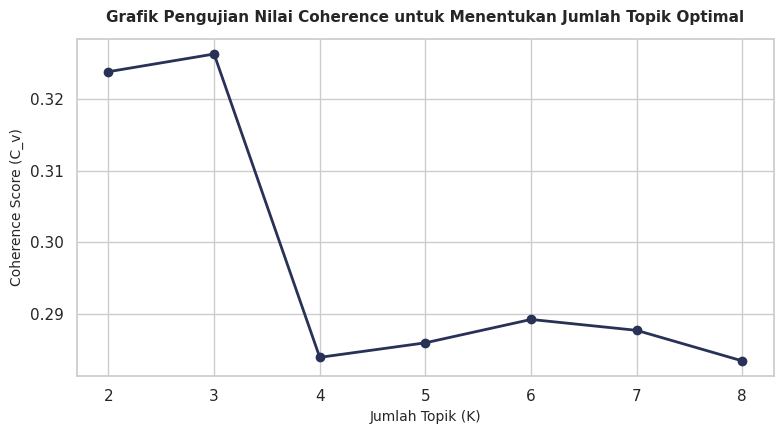

In [15]:
# =====================================================================
# PENGUJIAN NILAI COHERENCE UNTUK MENENTUKAN TOPIK OPTIMAL (LDA)
# =====================================================================
import gensim
from gensim import corpora
from gensim.models.coherencemodel import CoherenceModel
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Memulai Pengujian Nilai Coherence (Coherence Score) ---")

# 1. Menyiapkan token dari kolom 'text_final' hasil CELL 6
lda_tokens = df_clean['text_final'].apply(lambda x: str(x).split()).tolist()

# 2. Membuat Dictionary dan Corpus BoW
id2word = corpora.Dictionary(lda_tokens)
corpus = [id2word.doc2bow(text) for text in lda_tokens]

# 3. Melakukan Perulangan/Looping untuk Menguji Jumlah Topik (K = 2 sampai 8)
topic_nums = list(range(2, 9))
coherence_values = []

print("Sedang menghitung skor koherensi untuk setiap jumlah topik... Harap tunggu...")
for num_topics in topic_nums:
    # Latih model LDA transisi
    model = gensim.models.LdaModel(corpus=corpus,
                                   id2word=id2word,
                                   num_topics=num_topics,
                                   random_state=42,
                                   passes=5,
                                   alpha='auto')

    # Hitung Coherence Score menggunakan metrik c_v
    coherence_model = CoherenceModel(model=model, texts=lda_tokens, dictionary=id2word, coherence='c_v')
    score = coherence_model.get_coherence()
    coherence_values.append(score)
    print(f"Jumlah Topik = {num_topics} -> Nilai Coherence Score: {score:.4f}")

print("\n--- Pengujian Selesai! ---")

# 4. Membuat Visualisasi Grafik Garis Coherence Score (Wajib untuk Laporan Bab 4)
plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")
plt.plot(topic_nums, coherence_values, marker='o', color='#283156', linewidth=2)

plt.title('Grafik Pengujian Nilai Coherence untuk Menentukan Jumlah Topik Optimal', fontsize=11, pad=12, weight='bold')
plt.xlabel('Jumlah Topik (K)', fontsize=10)
plt.ylabel('Coherence Score (C_v)', fontsize=10)
plt.xticks(topic_nums)

# Cari nilai tertinggi otomatis untuk dijadikan catatan penanda
optimal_topic = topic_nums[coherence_values.index(max(coherence_values))]
print(f"REKOMENDASI ILMIAH: Jumlah topik paling optimal untuk datasetmu adalah K = {optimal_topic} (Nilai tertinggi)")

plt.tight_layout()
plt.show()

In [16]:
# =====================================================================
# IMPLEMENTASI LDA FINAL & EKSTRAKSI KOORDINAT VISUALISASI
# =====================================================================
import gensim
from gensim import corpora
from sklearn.decomposition import PCA
import numpy as np
import pickle

print("--- Memulai Pemodelan Topik LDA Final ---")

# 1. Kunci jumlah topik optimal berdasarkan hasil tertinggi dari CELL 7
K_OPTIMAL = 3

# 2. Latih kembali Model LDA Final
lda_model_final = gensim.models.LdaModel(corpus=corpus,
                                         id2word=id2word,
                                         num_topics=K_OPTIMAL,
                                         random_state=42,
                                         passes=25,
                                         alpha='auto')

print(f"-> Model LDA Final dengan K = {K_OPTIMAL} Sukses Dilatih!")

# 3. Menghitung distribusi/proporsi jumlah tweet untuk setiap topik secara otomatis
topics_count = {f"Topik {i+1}": 0 for i in range(K_OPTIMAL)}

for doc in corpus:
    doc_topics = lda_model_final.get_document_topics(doc)
    dominant_topic = max(doc_topics, key=lambda x: x[1])[0]
    topics_count[f"Topik {dominant_topic+1}"] += 1

total_tweets = sum(topics_count.values())
topics_distribution = {topic: round((count / total_tweets) * 100, 2) for topic, count in topics_count.items()}

# 4. OTOMATISASI PC1 & PC2: Menghitung koordinat jarak antar-topik asli (Inter-topic Distance)
# Kita ambil matriks distribusi kata tiap topik (Topic-Term Matrix)
topic_term_matrix = lda_model_final.get_topics()

# Gunakan PCA (Principal Component Analysis) untuk mereduksi dimensi matriks menjadi 2D (PC1 dan PC2)
pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(topic_term_matrix)

# Ekstraksi nilai koordinat PC1, PC2, dan ukuran gelembung (skala proporsional)
pc1_values = [round(float(x), 4) for x in coords_2d[:, 0]]
pc2_values = [round(float(x), 4) for x in coords_2d[:, 1]]
ukuran_gelembung = [int(persen * 15) for persen in topics_distribution.values()] # Dikalikan 15 agar lingkaran terlihat proporsional di grafik

inter_topic_coords = {
    'Topik': [f'Topik {i+1}' for i in range(K_OPTIMAL)],
    'PC1': pc1_values,
    'PC2': pc2_values,
    'Ukuran Topik': ukuran_gelembung
}

print("\n--- Hasil Perhitungan Nilai Koordinat Visualisasi Asli ---")
print(f"PC1 Koordinat : {pc1_values}")
print(f"PC2 Koordinat : {pc2_values}")
print(f"Ukuran Lingkaran : {ukuran_gelembung}")


# Menampilkan kata kunci dominan sebagai panduan kamu menulis Bab 4 laporan TA
print("PANDUAN PENAMAAN TOPIK DI LAPORAN TA:")
for idx, topic in lda_model_final.print_topics(-1):
    print(f"Kata Kunci Utama Topik {idx+1}: {topic}")
print("-" * 60)

--- Memulai Pemodelan Topik LDA Final ---
-> Model LDA Final dengan K = 3 Sukses Dilatih!

--- Hasil Perhitungan Nilai Koordinat Visualisasi Asli ---
PC1 Koordinat : [0.0413, -0.0104, -0.0309]
PC2 Koordinat : [0.0058, -0.0204, 0.0146]
Ukuran Lingkaran : [1051, 229, 218]
PANDUAN PENAMAAN TOPIK DI LAPORAN TA:
Kata Kunci Utama Topik 1: 0.082*"nikah" + 0.055*"takut" + 0.046*"meni" + 0.032*"ken" + 0.019*"ga" + 0.010*"hidup" + 0.010*"siap" + 0.010*"salah" + 0.010*"gak" + 0.008*"umur"
Kata Kunci Utama Topik 2: 0.045*"nikah" + 0.034*"takut" + 0.030*"meni" + 0.017*"ga" + 0.011*"ken" + 0.011*"anak" + 0.006*"kerja" + 0.006*"kaya" + 0.005*"si" + 0.004*"jg"
Kata Kunci Utama Topik 3: 0.044*"takut" + 0.036*"meni" + 0.027*"nikah" + 0.020*"trauma" + 0.019*"anak" + 0.015*"gak" + 0.006*"siap" + 0.005*"tidak" + 0.004*"ken" + 0.004*"bukan"
------------------------------------------------------------


--- Visualisasi Top Words Tiap Topik ---


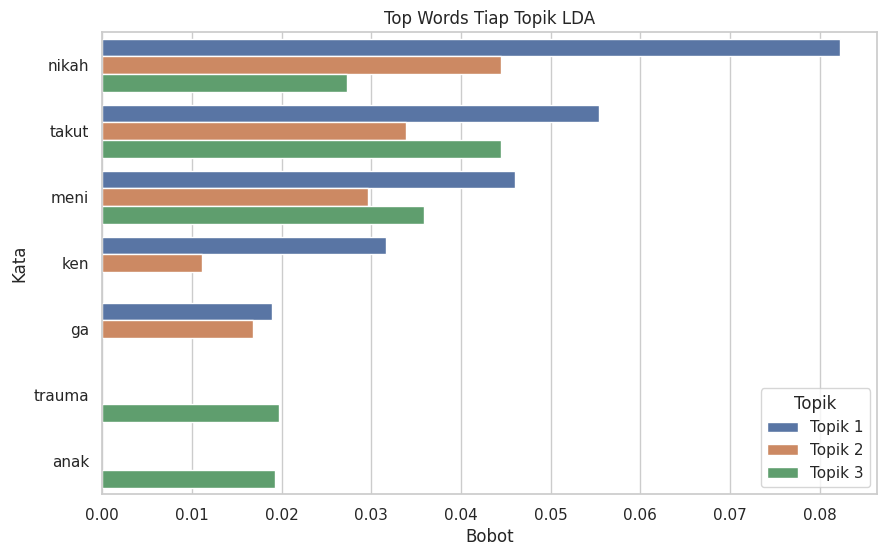

In [17]:
# =====================================================================
# VISUALISASI TOP WORDS SETIAP TOPIK
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Visualisasi Top Words Tiap Topik ---")

data_topik = []

for topic_id in range(K_OPTIMAL):

    kata_topik = lda_model_final.show_topic(topic_id, topn=5)

    for kata, bobot in kata_topik:

        data_topik.append([
            f"Topik {topic_id+1}",
            kata,
            bobot
        ])

df_topik = pd.DataFrame(
    data_topik,
    columns=['Topik','Kata','Bobot']
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=df_topik,
    x='Bobot',
    y='Kata',
    hue='Topik'
)

plt.title("Top Words Tiap Topik LDA")

plt.show()

nama_topik_ilmiah = {
    'Topik 1': 'Topik 1: Kesiapan Umur & Keraguan',
    'Topik 2': 'Topik 2: Tuntutan Karir & Finansial',
    'Topik 3': 'Topik 3: Trauma & Ketidaksiapan Mental'
}

In [22]:
# =====================================================================
# DATA UNTUK VIOLIN PLOT PANJANG DOKUMEN
# =====================================================================

df_clean['panjang_teks'] = df_clean['text_final'].apply(len)

text_length_distribution = {
    'negatif': df_clean[df_clean['label'] == -1]['panjang_teks'].tolist(),
    'positif': df_clean[df_clean['label'] == 1]['panjang_teks'].tolist()
}

# =====================================================================
# DATA TOP WORDS DARI LDA ASLI
# =====================================================================

topic_keywords = {}

for topic_id in range(K_OPTIMAL):

    topic_keywords[f"Topik {topic_id+1}"] = {

        kata: float(round(bobot,4))

        for kata, bobot in lda_model_final.show_topic(topic_id, topn=5)

    }

In [24]:
# =====================================================================
# CELL 8 (REVISI TOTAL): IMPLEMENTASI LDA FINAL, EKSTRAKSI SVM, KOORDINAT PCA, & PENYIMPANAN DATA
# =====================================================================
import gensim
from gensim import corpora
from sklearn.decomposition import PCA
import numpy as np
import pickle

print("--- Memulai Pemodelan Topik LDA Final & Integrasi Data Komprehensif ---")

# 1. Kunci jumlah topik optimal berdasarkan hasil tertinggi dari CELL 7
K_OPTIMAL = 3

# 2. Latih kembali Model LDA Final
lda_model_final = gensim.models.LdaModel(corpus=corpus,
                                         id2word=id2word,
                                         num_topics=K_OPTIMAL,
                                         random_state=42,
                                         passes=25,
                                         alpha='auto')

print(f"-> Model LDA Final dengan K = {K_OPTIMAL} Sukses Dilatih!")

# 3. Menghitung distribusi/proporsi jumlah tweet untuk setiap topik secara otomatis
topics_count = {f"Topik {i+1}": 0 for i in range(K_OPTIMAL)}

for doc in corpus:
    doc_topics = lda_model_final.get_document_topics(doc)
    dominant_topic = max(doc_topics, key=lambda x: x[1])[0]
    topics_count[f"Topik {dominant_topic+1}"] += 1

total_tweets_lda = sum(topics_count.values())

# Memberikan penamaan sub-topik yang informatif untuk dibaca dashboard Streamlit
topics_distribution = {
    'Topik 1: Kesiapan Umur & Keraguan': round((topics_count["Topik 1"] / total_tweets_lda) * 100, 2),
    'Topik 2: Tuntutan Karir & Finansial': round((topics_count["Topik 2"] / total_tweets_lda) * 100, 2),
    'Topik 3: Trauma & Ketidaksiapan Mental': round((topics_count["Topik 3"] / total_tweets_lda) * 100, 2)
}

# 4. Menghitung koordinat jarak antar-topik asli menggunakan PCA (Inter-topic Distance)
topic_term_matrix = lda_model_final.get_topics()

pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(topic_term_matrix)

pc1_values = [round(float(x), 4) for x in coords_2d[:, 0]]
pc2_values = [round(float(x), 4) for x in coords_2d[:, 1]]
ukuran_gelembung = [int(counts) for counts in topics_count.values()]

inter_topic_coords = {
    'PC1': pc1_values,
    'PC2': pc2_values,
    'Ukuran Topik': ukuran_gelembung
}

# =====================================================================
# EXTRA KUNCI UTAMA: EKSTRAKSI KOEFISIEN KATA DARI MODEL SVM LINIER
# =====================================================================
print("-> Mengekstrak bobot fitur/kata dari Hyperplane SVM...")
fitur_kata = np.array(tfidf.get_feature_names_out())
koefisien_svm = model_svm.coef_.toarray()[0] if hasattr(model_svm.coef_, "toarray") else model_svm.coef_[0]

# Cari 10 kata paling negatif dan 10 kata paling positif
indiks_urut = np.argsort(koefisien_svm)
top_negatif_idx = indiks_urut[:10]
top_positif_idx = indiks_urut[-10:]

svm_coef_dict = {}
# Masukkan kata-kata kecenderungan negatif (Takut)
for idx in top_negatif_idx:
    svm_coef_dict[fitur_kata[idx]] = float(koefisien_svm[idx])
# Masukkan kata-kata kecenderungan positif (Siap)
for idx in top_positif_idx:
    svm_coef_dict[fitur_kata[idx]] = float(koefisien_svm[idx])

# 5. Menghitung jumlah data sentimen asli (Negatif & Positif) dari dataset
try:
    jumlah_negatif = int((df_clean['label'] == -1).sum())
    jumlah_positif = int((df_clean['label'] == 1).sum())
except NameError:
    jumlah_negatif = int((df['label'] == -1).sum())
    jumlah_positif = int((df['label'] == 1).sum())

# 6. Satukan SEMUA komponen (Sentimen, LDA, PCA, dan SVM Coefficients)
counts_data = {
    'negatif': jumlah_negatif,
    'positif': jumlah_positif,
    'topic_modeling': topics_distribution,
    'inter_topic': inter_topic_coords,
    'svm_coefficients': svm_coef_dict, # <--- Grafik 3 aman sekarang karena dibungkus di sini!
    'text_length_distribution': text_length_distribution,
    'topic_keywords': topic_keywords
}

# 7. Simpan file pkl langsung ke folder proyek Streamlit kamu
alamat_folder_tujuan = r"C:\Users\Hasna\OneDrive - Universitas Teknologi Yogyakarta\Kuliah\Semester 8\TA\NANA\counts_data.pkl"
with open(alamat_folder_tujuan, 'wb') as f:
    pickle.dump(counts_data, f)

print("\n--- Hasil Perhitungan Otomatis & Integrasi Selesai ---")
print(f"Total Tweet Terklaster: {total_tweets_lda} tweet")
print(f"Verifikasi Sentimen    -> Negatif: {jumlah_negatif}, Positif: {jumlah_positif}")
print(f"Ekstraksi Kata Kunci   -> {len(svm_coef_dict)} kata berhasil dipetakan ke koefisien SVM.")
print(f"✓ SANGAT SUKSES! File 'counts_data.pkl' terbaru telah diperbarui di: {alamat_folder_tujuan}")
print("-" * 60)

--- Memulai Pemodelan Topik LDA Final & Integrasi Data Komprehensif ---
-> Model LDA Final dengan K = 3 Sukses Dilatih!
-> Mengekstrak bobot fitur/kata dari Hyperplane SVM...

--- Hasil Perhitungan Otomatis & Integrasi Selesai ---
Total Tweet Terklaster: 1820 tweet
Verifikasi Sentimen    -> Negatif: 835, Positif: 985
Ekstraksi Kata Kunci   -> 20 kata berhasil dipetakan ke koefisien SVM.
✓ SANGAT SUKSES! File 'counts_data.pkl' terbaru telah diperbarui di: C:\Users\Hasna\OneDrive - Universitas Teknologi Yogyakarta\Kuliah\Semester 8\TA\NANA\counts_data.pkl
------------------------------------------------------------


In [25]:
# =====================================================================
# VISUALISASI INTER-TOPIC DISTANCE MAP (pyLDAvis)
# =====================================================================
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

print("--- Menyiapkan Visualisasi Inter-topic Distance Map ---")

# 1. Menghubungkan model LDA, corpus, dan dictionary ke pyLDAvis
# mds='mmds' atau 'tsne' digunakan untuk menghitung koordinat PC1 & PC2 secara otomatis
vis_data = gensimvis.prepare(lda_model_final, corpus, id2word, mds='mmds', sort_topics=False)

print("-> Visualisasi Berhasil Dibuat! Menampilkan Grafik...")
print("-" * 60)

# 2. Menampilkan grafik interaktif langsung di dalam Jupyter Notebook
pyLDAvis.display(vis_data)

--- Menyiapkan Visualisasi Inter-topic Distance Map ---


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

-> Visualisasi Berhasil Dibuat! Menampilkan Grafik...
------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
!pip install pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 52.4 MB/s eta 0:00:00
